# Ephraim's fraud models (PBI 08)
Kochuveettil Toji Ephraim, AMLOPS CA1, ML Experiments

I am trying to predict which orders are fraud, using the order details and one customer history feature. I train two models, a decision tree and a random forest. Each one starts as a baseline with default settings and then I tune it. The two tuned versions are the models I hand in.

The three cleaned csv files sit in the same folder as this notebook. Cleaning (PBI 02) and the order features plus the date split (PBI 03) are the team's code in `src`. All the model code is in this notebook.

## 1. Imports and MLflow target
The MLflow cell has to run before any training or logging cell. If it runs later, runs that were already logged stay in the local MLflow store and do not go to the shared server.

In [68]:
import hashlib
import io
import itertools
import os
import tempfile
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.tree import DecisionTreeClassifier

from src.feature_engineering import (
    CUSTOMER_KEY, INPUT_FEATURES, ORDER_KEY, fit_preprocessor, prepare_training_data,
)

HISTORY = "days_since_first_order"
THRESHOLD = 0.50
SEED = 42

In [69]:
import mlflow

# the shared mlflow server address comes from settings, not from this notebook (PBI 11)
SHARED_MLFLOW_URI = os.environ.get("MLFLOW_TRACKING_URI", "").strip()
if not SHARED_MLFLOW_URI:
    raise RuntimeError("Set MLFLOW_TRACKING_URI to the shared MLflow server URL before starting "
                       "Jupyter. See docs/PBI11_CONFIGURATION.md.")
mlflow.set_tracking_uri(SHARED_MLFLOW_URI)

print("MLflow target:", os.environ["MLFLOW_TRACKING_URI"])
# connection test: should print the experiment names
print([e.name for e in mlflow.search_experiments()])

MLflow target: http://mlflow-pbi12.eba-9bnrxizu.us-east-1.elasticbeanstalk.com
['PBI06_HanQian', 'PBI08_Ephraim', 'PBI07_Nithish', 'pbi12-persistence-check', 'Default']


## 2. Load the data and split it
PBI 03 gives seven order features and splits the orders by date into 70% train, 15% validation and 15% test. Whole days stay together. I only ask for train and validation (`include_test=False`), so the test period is never loaded.

I add one feature from the customer file, the number of days between the order and the customer's first recorded purchase. It is left empty when the first purchase date is missing or later than the order.

In [70]:
# cleaned csvs are in the same folder as this notebook
# ids are read as text so pandas does not turn them into numbers
customers = pd.read_csv("customers_cleaned.csv", dtype={"country_code": str, "customer_id": str})
orders = pd.read_csv("orders_cleaned.csv", dtype={"country_code": str, "order_id": str})
labels = pd.read_csv("labels_cleaned.csv", dtype={"country_code": str, "order_id": str, "customer_id": str})

x_train, y_train, x_val, y_val, _, _, split_report, train_dates = prepare_training_data(
    customers, orders, labels, include_test=False, include_training_dates=True
)

# days since first order: same merge as prepare_training_data uses, so the row index lines up
rows = labels[ORDER_KEY + ["customer_id"]].reset_index(drop=True).merge(
    orders[ORDER_KEY + ["order_date", "order_value"]], on=ORDER_KEY, how="left", validate="one_to_one")
rows = rows.merge(customers[CUSTOMER_KEY + ["first_order_datetime"]], on=CUSTOMER_KEY, how="left", validate="many_to_one")
history = (pd.to_datetime(rows["order_date"]).dt.normalize()
           - pd.to_datetime(rows["first_order_datetime"]).dt.normalize()).dt.days.astype(float)
history = history.where(history >= 0)
for name, frame in (("train", x_train), ("validation", x_val)):
    assert np.allclose(rows.loc[frame.index, "order_value"].astype(float), frame["order_value"], equal_nan=True), name
x_train = x_train.assign(**{HISTORY: history.loc[x_train.index]})
x_val = x_val.assign(**{HISTORY: history.loc[x_val.index]})

print("Train     :", x_train.shape, train_dates.min().date(), "to", train_dates.max().date())
print("Validation:", x_val.shape, split_report["validation_first_date"], "to", split_report["validation_last_date"])
print("\nFraud counts")
print(pd.DataFrame({"train": y_train.value_counts(), "validation": y_val.value_counts()}))
print("\nFraud rate: train", round(y_train.mean(), 4), "| validation", round(y_val.mean(), 4))
print("\nFeatures:", list(x_train.columns))
x_train.head()

C:\Users\ephra\AppData\Local\Temp\ipykernel_47016\274435436.py:3: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  customers = pd.read_csv("customers_cleaned.csv", dtype={"country_code": str, "customer_id": str})


Train     : (660773, 8) 2022-11-12 to 2023-03-14
Validation: (144978, 8) 2023-03-15 to 2023-04-13

Fraud counts
           train  validation
is_fraud                    
0         593926      125238
1          66847       19740

Fraud rate: train 0.1012 | validation 0.1362

Features: ['order_value', 'num_items_ordered', 'order_weekday', 'order_month', 'country_code', 'collect_type', 'payment_method', 'days_since_first_order']


,order_value,num_items_ordered,order_weekday,order_month,country_code,collect_type,payment_method,days_since_first_order
0,13.877272,1.0,5.0,12.0,TH,delivery,payment on Delivery,1250.0
2,4.309368,3.0,2.0,11.0,PH,delivery,payment on Delivery,138.0
3,8.090340,1.0,0.0,1.0,MY,delivery,credit card,939.0
5,5.398007,2.0,1.0,12.0,MY,delivery,cybersource,1248.0
6,2.119430,1.0,3.0,11.0,MY,delivery,payment on Delivery,551.0


## 3. Helper functions
`build_preprocessor` fits the PBI 03 preprocessing and a median imputer for the history feature, using only the rows it is given. `evaluate` calculates the fraud metrics at a fixed 0.50 cutoff.

In [71]:
def build_preprocessor(rows_fit):
    shared = fit_preprocessor(rows_fit[INPUT_FEATURES])
    history_step = ColumnTransformer([
        ("customer_history", SimpleImputer(strategy="median", keep_empty_features=True), [HISTORY]),
    ]).fit(rows_fit)
    return FeatureUnion([("shared", shared), ("history", history_step)])


def fraud_score(estimator, matrix):
    return estimator.predict_proba(matrix)[:, list(estimator.classes_).index(1)]


def evaluate(y_true, scores, threshold=THRESHOLD):
    predicted = (np.asarray(scores) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {
        "precision": precision_score(y_true, predicted, zero_division=0),
        "recall": recall_score(y_true, predicted, zero_division=0),
        "f1": f1_score(y_true, predicted, zero_division=0),
        "average_precision": average_precision_score(y_true, scores),
        "roc_auc": roc_auc_score(y_true, scores),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "flag_rate": float(predicted.mean()),
    }


# preprocessing for the final models, fitted on the training period only
preprocessor = build_preprocessor(x_train)
train_matrix = preprocessor.transform(x_train)
val_matrix = preprocessor.transform(x_val)
print("Matrix shapes:", train_matrix.shape, val_matrix.shape)

Matrix shapes: (660773, 32) (144978, 32)


## 4. Load the saved weights
If the four models were already trained and saved in `saved_models`, they are loaded here and the training and tuning cells below are skipped. If any file is missing, everything is trained from scratch.

In [72]:
names = ["dt_baseline", "dt_tuned", "rf_baseline", "rf_tuned"]
SAVE_DIR = Path("saved_models")
files = {name: SAVE_DIR / f"{name}.joblib" for name in names}

fitted = {}
fit_seconds = {}
loaded = all(path.exists() for path in files.values())

if loaded:
    for name, path in files.items():
        fitted[name] = joblib.load(path).named_steps["classifier"]
    # use the saved preprocessing too, so the columns match the saved models
    preprocessor = joblib.load(files["dt_baseline"]).named_steps["preprocessor"]
    train_matrix = preprocessor.transform(x_train)
    val_matrix = preprocessor.transform(x_val)
    print("Loaded saved weights for:", names)
else:
    print("No complete set of saved weights, the models will be trained below.")

Loaded saved weights for: ['dt_baseline', 'dt_tuned', 'rf_baseline', 'rf_tuned']


## 5. Baselines
First a dummy model that always says not fraud. It shows why accuracy is a bad measure here, since it looks good on accuracy and finds no fraud at all.

Model 1 is the decision tree from my AIML CA1 with seed 42 and default settings. Model 2 is a default random forest with 30 trees, so it stays workable on 660k rows. Both are fitted on the whole training period. The baseline tree takes a few minutes to fit.

In [73]:
dummy = DummyClassifier(strategy="most_frequent").fit(train_matrix, y_train)
results = {"dummy": evaluate(y_val, dummy.predict(val_matrix))}

if not loaded:
    start = time.perf_counter()
    fitted["dt_baseline"] = DecisionTreeClassifier(random_state=SEED).fit(train_matrix, y_train)
    fit_seconds["dt_baseline"] = time.perf_counter() - start

    start = time.perf_counter()
    fitted["rf_baseline"] = RandomForestClassifier(n_estimators=30, random_state=SEED, n_jobs=-1).fit(train_matrix, y_train)
    fit_seconds["rf_baseline"] = time.perf_counter() - start

for name in ("dt_baseline", "rf_baseline"):
    results[name] = evaluate(y_val, fraud_score(fitted[name], val_matrix))
print({k: round(v, 1) for k, v in fit_seconds.items()}, "seconds")
display(pd.DataFrame(results).round(4))

{} seconds


,dummy,dt_baseline,rf_baseline
precision,0.0000,0.3995,0.6226
recall,0.0000,0.3382,0.2845
f1,0.0000,0.3663,0.3906
average_precision,0.1362,0.2253,0.4630
roc_auc,0.5000,0.6292,0.8069
tn,125238.0000,115201.0000,121833.0000
fp,0.0000,10037.0000,3405.0000
fn,19740.0000,13063.0000,14123.0000
tp,0.0000,6677.0000,5617.0000
flag_rate,0.0000,0.1153,0.0622


## 6. Folds for tuning
To tune without touching validation I make two folds inside the training period, in date order. The preprocessing is fitted again on each fold's earlier rows, so nothing from the later dates leaks in.

Fold 1 fits on the first 60% of the training dates and checks on the next 20%. Fold 2 fits on the first 80% and checks on the last 20%.

In [74]:
folds = []

if not loaded:
    dates_sorted = pd.Index(train_dates.unique()).sort_values()
    d60 = dates_sorted[int(len(dates_sorted) * 0.60)]
    d80 = dates_sorted[int(len(dates_sorted) * 0.80)]
    fold_bounds = [(d60, d80), (d80, None)]  # (fit before this date, check before this date)

    for fit_before, check_before in fold_bounds:
        fit_rows = train_dates < fit_before
        check_rows = (train_dates >= fit_before) & ((train_dates < check_before) if check_before is not None else True)
        pre = build_preprocessor(x_train.loc[fit_rows])
        folds.append({
            "fit_x": pre.transform(x_train.loc[fit_rows]), "fit_y": y_train.loc[fit_rows],
            "check_x": pre.transform(x_train.loc[check_rows]), "check_y": y_train.loc[check_rows],
        })
        print(f"fold: fit {fit_rows.sum()} rows (before {fit_before.date()}), check {check_rows.sum()} rows, "
              f"check fraud rate {y_train.loc[check_rows].mean():.3f}")


def cross_check(make_estimator):
    # average result over the folds for one set of settings
    out = {"fit_f1": [], "check_f1": [], "check_ap": [], "check_fp": [], "check_fn": []}
    for fold in folds:
        est = make_estimator().fit(fold["fit_x"], fold["fit_y"])
        fit_m = evaluate(fold["fit_y"], fraud_score(est, fold["fit_x"]))
        chk_m = evaluate(fold["check_y"], fraud_score(est, fold["check_x"]))
        out["fit_f1"].append(fit_m["f1"]); out["check_f1"].append(chk_m["f1"])
        out["check_ap"].append(chk_m["average_precision"])
        out["check_fp"].append(chk_m["fp"]); out["check_fn"].append(chk_m["fn"])
    return {k: float(np.mean(v)) for k, v in out.items()}

## 7. Tune model 1, the decision tree
The first row of the table below is the baseline. If its F1 on the rows it was fitted on is much higher than its F1 on the later dates, the tree is memorising. The other rows try a depth limit, a minimum leaf size and class weighting. I keep the setting with the best average F1 on the later dates of the folds.

In [75]:
if loaded:
    est = fitted["dt_tuned"]
    dt_params = {"max_depth": est.max_depth, "min_samples_leaf": est.min_samples_leaf, "class_weight": est.class_weight}
    print("Tuned decision tree settings (from the saved model):", dt_params)
else:
    start = time.perf_counter()
    dt_rows = [{"depth": None, "leaf": 1, "class_weight": None,
                **cross_check(lambda: DecisionTreeClassifier(random_state=SEED))}]  # the baseline
    for depth, leaf, cw in itertools.product([6, 10, 14], [20, 100], [None, "balanced"]):
        dt_rows.append({"depth": depth, "leaf": leaf, "class_weight": cw,
                        **cross_check(lambda: DecisionTreeClassifier(random_state=SEED, max_depth=depth,
                                                                     min_samples_leaf=leaf, class_weight=cw))})
    dt_search = pd.DataFrame(dt_rows).sort_values(["check_f1", "check_ap"], ascending=False)
    display(dt_search.round(4))
    print(f"{time.perf_counter() - start:.0f} s")

    best = dt_search.iloc[0]
    dt_params = {"max_depth": None if pd.isna(best["depth"]) else int(best["depth"]),
                 "min_samples_leaf": int(best["leaf"]),
                 "class_weight": None if pd.isna(best["class_weight"]) else best["class_weight"]}
    print("Baseline F1 on fitted rows vs later dates:", round(dt_rows[0]["fit_f1"], 3), "vs", round(dt_rows[0]["check_f1"], 3))
    print("Tuned decision tree settings:", dt_params)

Tuned decision tree settings (from the saved model): {'max_depth': 10, 'min_samples_leaf': 20, 'class_weight': 'balanced'}


## 8. Tune model 2, the random forest
Same folds and the same rule for picking the best setting. The grid covers depth, leaf size and class weighting.

In [76]:
if loaded:
    est = fitted["rf_tuned"]
    rf_params = {"max_depth": est.max_depth, "min_samples_leaf": est.min_samples_leaf, "class_weight": est.class_weight}
    print("Tuned random forest settings (from the saved model):", rf_params)
else:
    start = time.perf_counter()
    rf_rows = []
    for depth, leaf, cw in itertools.product([10, 14], [20, 50], [None, "balanced"]):
        rf_rows.append({"depth": depth, "leaf": leaf, "class_weight": cw,
                        **cross_check(lambda: RandomForestClassifier(n_estimators=30, random_state=SEED, n_jobs=-1,
                                                                     max_depth=depth, min_samples_leaf=leaf, class_weight=cw))})
    rf_search = pd.DataFrame(rf_rows).sort_values(["check_f1", "check_ap"], ascending=False)
    display(rf_search.round(4))
    print(f"{time.perf_counter() - start:.0f} s")

    best = rf_search.iloc[0]
    rf_params = {"max_depth": int(best["depth"]), "min_samples_leaf": int(best["leaf"]),
                 "class_weight": None if pd.isna(best["class_weight"]) else best["class_weight"]}
    print("Tuned random forest settings:", rf_params)

Tuned random forest settings (from the saved model): {'max_depth': 14, 'min_samples_leaf': 20, 'class_weight': 'balanced'}


## 9. Fit the tuned versions
Each tuned model is refitted on the whole training period with the same preprocessing as its baseline. Validation is scored once per model.

In [77]:
if not loaded:
    start = time.perf_counter()
    fitted["dt_tuned"] = DecisionTreeClassifier(random_state=SEED, **dt_params).fit(train_matrix, y_train)
    fit_seconds["dt_tuned"] = time.perf_counter() - start

    start = time.perf_counter()
    fitted["rf_tuned"] = RandomForestClassifier(n_estimators=30, random_state=SEED, n_jobs=-1, **rf_params).fit(train_matrix, y_train)
    fit_seconds["rf_tuned"] = time.perf_counter() - start

for name in ("dt_tuned", "rf_tuned"):
    results[name] = evaluate(y_val, fraud_score(fitted[name], val_matrix))
print({k: round(v, 1) for k, v in fit_seconds.items()}, "seconds")

{} seconds


## 10. Compare on validation
Precision is the share of flagged orders that really were fraud. Recall is the share of all fraud that got flagged. F1 combines the two. Average precision and ROC-AUC show how well the model ranks orders. I also look at false alarms (fp), missed fraud (fn) and the share of orders flagged, since that is the work the analysts get.

,dummy,dt_baseline,dt_tuned,rf_baseline,rf_tuned,dt tuned minus baseline,rf tuned minus baseline
precision,0.0000,0.3995,0.3982,0.6226,0.4003,-0.0013,-0.2223
recall,0.0000,0.3382,0.7806,0.2845,0.8047,0.4424,0.5201
f1,0.0000,0.3663,0.5274,0.3906,0.5346,0.1611,0.1441
average_precision,0.1362,0.2253,0.5024,0.4630,0.5390,0.2771,0.0761
roc_auc,0.5000,0.6292,0.8470,0.8069,0.8583,0.2178,0.0514
tn,125238.0000,115201.0000,101951.0000,121833.0000,101442.0000,-13250.0000,-20391.0000
fp,0.0000,10037.0000,23287.0000,3405.0000,23796.0000,13250.0000,20391.0000
fn,19740.0000,13063.0000,4330.0000,14123.0000,3856.0000,-8733.0000,-10267.0000
tp,0.0000,6677.0000,15410.0000,5617.0000,15884.0000,8733.0000,10267.0000
flag_rate,0.0000,0.1153,0.2669,0.0622,0.2737,0.1516,0.2115


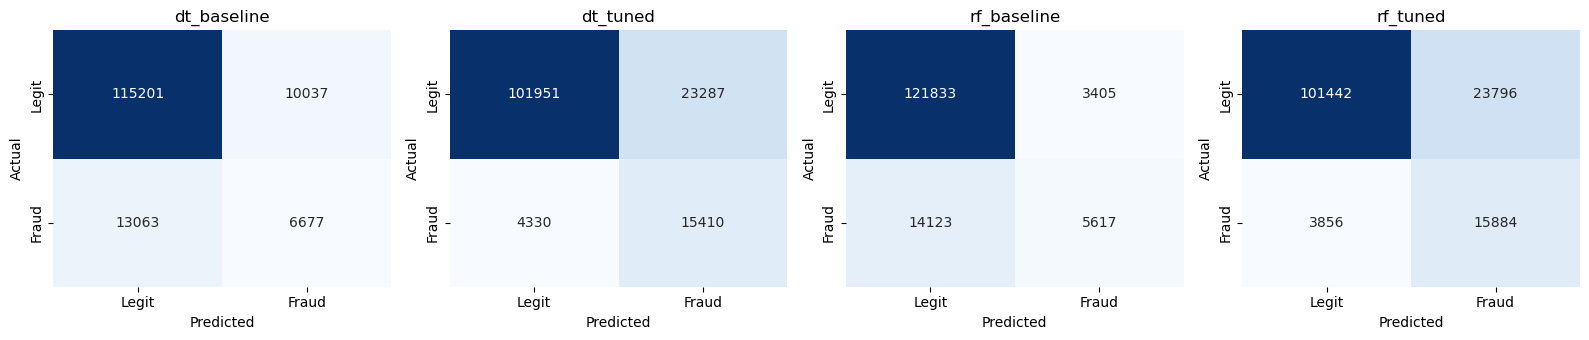

dt_baseline
              precision    recall  f1-score   support

           0       0.90      0.92      0.91    125238
           1       0.40      0.34      0.37     19740

    accuracy                           0.84    144978
   macro avg       0.65      0.63      0.64    144978
weighted avg       0.83      0.84      0.84    144978

dt_tuned
              precision    recall  f1-score   support

           0       0.96      0.81      0.88    125238
           1       0.40      0.78      0.53     19740

    accuracy                           0.81    144978
   macro avg       0.68      0.80      0.70    144978
weighted avg       0.88      0.81      0.83    144978

rf_baseline
              precision    recall  f1-score   support

           0       0.90      0.97      0.93    125238
           1       0.62      0.28      0.39     19740

    accuracy                           0.88    144978
   macro avg       0.76      0.63      0.66    144978
weighted avg       0.86      0.88      0.

In [78]:
comparison = pd.DataFrame(results)[["dummy", "dt_baseline", "dt_tuned", "rf_baseline", "rf_tuned"]]
comparison["dt tuned minus baseline"] = comparison["dt_tuned"] - comparison["dt_baseline"]
comparison["rf tuned minus baseline"] = comparison["rf_tuned"] - comparison["rf_baseline"]
display(comparison.round(4))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, name in zip(axes, names):
    m = results[name]
    sns.heatmap([[m["tn"], m["fp"]], [m["fn"], m["tp"]]], annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False,
                xticklabels=["Legit", "Fraud"], yticklabels=["Legit", "Fraud"])
    ax.set(xlabel="Predicted", ylabel="Actual", title=name)
fig.tight_layout()
plt.show()

for name in names:
    print(name)
    pred = (fraud_score(fitted[name], val_matrix) >= THRESHOLD).astype(int)
    print(classification_report(y_val, pred, labels=[0, 1], zero_division=0))

## 11. What the results show
**Diagnosis.** The baseline tree is grown until every leaf is pure, so it memorises the training rows. In my first diagnostic run I fitted it on the older 80% of the training dates and checked it on the newest 20%. Its F1 fell from about 0.999 on the rows it had seen to about 0.306 on the later dates. On the real validation set the baseline tree scored an F1 of 0.366. That gap is what overfitting looks like.

The other problem is that both baselines flag very few orders. They flag 11.6% (tree) and 6.2% (forest) of orders while 13.6% of validation orders are fraud. They miss 13,063 and 14,123 fraud orders. So the two things to fix were too much memorising and too little fraud being flagged.

**Change.** I did not choose settings by looking at validation. I tuned on the two date folds inside the training period only. The tree grid tried depth limits, minimum leaf sizes and class weighting. The forest grid tried the same except for the tree depth values. The setting with the best average F1 on the later fold dates was refitted on all the training rows. The settings that won are printed in sections 7 and 8.

**Outcome.** These are the validation results at the 0.50 cutoff. The baseline rows come from my first run and the tuned rows from the run that gave the saved weights.

| Model | F1 | Precision | Recall | False alarms | Missed fraud | Share flagged |
|---|---|---|---|---|---|---|
| Tree baseline | 0.366 | 0.398 | 0.338 | 10,082 | 13,063 | 11.6% |
| Tree tuned | 0.527 | 0.398 | 0.781 | 23,287 | 4,330 | 26.7% |
| Forest baseline | 0.391 | 0.623 | 0.285 | 3,405 | 14,123 | 6.2% |
| Forest tuned | 0.535 | 0.400 | 0.805 | 23,796 | 3,856 | 27.4% |

Tuning raised F1 by about 0.16 for the tree and 0.14 for the forest. The gain comes from recall, which went from under 35% to about 80%. Precision stayed the same for the tree and dropped for the forest. The price is the review workload. The analysts now get about 27% of all orders to check instead of 6 to 12%, and roughly 23,000 normal orders get flagged. Whether that is acceptable depends on how many orders the team can really review. The forest is only a little better than the tree (0.535 against 0.527) and it is the bigger and slower model.

**Limits.** Validation has a higher fraud rate than training (13.6% against 10.1%), so the scores may move on newer data. The cutoff is fixed at 0.50 and I did not tune it. The final test period has not been used. If the numbers change when this notebook is rerun, the table above needs updating by hand.

## 12. Save the weights
Every model is saved together with its preprocessing as one pipeline file in `saved_models` (joblib). To use one, load it with `joblib.load` and call `predict_proba` on a frame with the 8 input features, the same columns as `x_val`. A fraud probability of 0.50 or more counts as flagged.

If the weights were loaded in section 4 this cell does not overwrite them.

In [79]:
SAVE_DIR.mkdir(exist_ok=True)

if loaded:
    print("Weights were loaded from disk, nothing to save.")
else:
    to_save = {name: Pipeline([("preprocessor", preprocessor), ("classifier", fitted[name])]) for name in names}

    for name, pipeline in to_save.items():
        path = SAVE_DIR / f"{name}.joblib"
        joblib.dump(pipeline, path, compress=3)
        print(f"{path}  {path.stat().st_size / 1e6:.1f} MB")

    # reload one and check it gives the same scores
    check = joblib.load(SAVE_DIR / "dt_tuned.joblib")
    np.testing.assert_allclose(check.predict_proba(x_val.head(10))[:, 1], fraud_score(fitted["dt_tuned"], val_matrix[:10]))
    print("reload check passed")

Weights were loaded from disk, nothing to save.


## 13. Log to the shared MLflow
Each model gets one run with its settings, metrics, split info and tuning info. The shared server refuses big uploads (error 413), so the model file is tried normally first. If that is rejected, the whole pipeline is compressed and uploaded in small numbered parts, then downloaded again and checked against the original predictions. The two baselines are fully grown trees that are too big even in parts, so only their settings and metrics are logged.

`load_model_from_chunks(run_id)` rebuilds a model that was uploaded in parts.

In [80]:
CHUNK_MB = 0.5  # small enough for the server's upload limit


def upload_model_in_chunks(pipeline, chunk_mb=CHUNK_MB):
    import mlflow
    buffer = io.BytesIO()
    joblib.dump(pipeline, buffer, compress=9)
    data = buffer.getvalue()
    size = int(chunk_mb * 1e6)
    parts = [data[i:i + size] for i in range(0, len(data), size)]
    with tempfile.TemporaryDirectory() as folder:
        for n, part in enumerate(parts):
            path = os.path.join(folder, f"part_{n:04d}.bin")
            with open(path, "wb") as handle:
                handle.write(part)
            mlflow.log_artifact(path, artifact_path="model_chunks")
    mlflow.log_dict({"parts": len(parts), "bytes": len(data), "sha256": hashlib.sha256(data).hexdigest(),
                     "how_to_load": "join the parts in order, then joblib.load"},
                    "model_chunks/manifest.json")
    return len(parts), len(data) / 1e6


def load_model_from_chunks(run_id):
    import json
    import mlflow
    folder = mlflow.artifacts.download_artifacts(run_id=run_id, artifact_path="model_chunks")
    manifest = json.load(open(os.path.join(folder, "manifest.json")))
    data = b"".join(open(os.path.join(folder, f"part_{n:04d}.bin"), "rb").read() for n in range(manifest["parts"]))
    assert hashlib.sha256(data).hexdigest() == manifest["sha256"], "model parts are corrupted"
    return joblib.load(io.BytesIO(data))


def log_model_run(name, estimator, metrics, tracking_uri, params, upload_model):
    import cloudpickle
    import mlflow, mlflow.sklearn
    from mlflow.models import infer_signature

    full_model = Pipeline([("preprocessor", preprocessor), ("classifier", estimator)])
    family, stage = name.split("_")
    mlflow.set_tracking_uri(tracking_uri)
    mlflow.set_experiment("PBI08_Ephraim")
    with mlflow.start_run(run_name=f"pbi08/base/{name}",
                          tags={"member": "Ephraim", "pbi": "08", "model": family, "stage": stage}) as run:
        mlflow.log_params({f"clf_{k}": v for k, v in estimator.get_params().items()})
        mlflow.log_params({"threshold": THRESHOLD, "seed": SEED, "features": ",".join(x_val.columns)})
        mlflow.log_metrics({k: float(v) for k, v in metrics.items()})
        if name in fit_seconds:
            mlflow.log_metric("fit_seconds", fit_seconds[name])
        mlflow.log_dict({k: str(v) for k, v in split_report.items()}, "split.json")
        mlflow.log_dict({"tuned_settings": params}, "tuning.json")
        if not upload_model:
            mlflow.set_tag("model_artifact", "not uploaded, too big for the shared server (weights saved locally)")
            return run.info.run_id, None
        size_mb = len(cloudpickle.dumps(full_model)) / 1e6
        print(f"  uploading {name} model ({size_mb:.1f} MB)")
        sample = x_val.head(10)
        try:
            info = mlflow.sklearn.log_model(full_model, artifact_path="model", input_example=sample,
                                            signature=infer_signature(sample, full_model.predict_proba(sample)),
                                            serialization_format="cloudpickle")
            restored = mlflow.sklearn.load_model(info.model_uri)
            np.testing.assert_allclose(restored.predict_proba(sample), full_model.predict_proba(sample))
            mlflow.log_metric("artifact_reload_verified", 1)
        except Exception as error:  # 413 means the server's nginx upload limit
            print(f"  normal upload rejected ({str(error)[:60]}). Trying small parts instead.")
            try:
                n_parts, mb = upload_model_in_chunks(full_model)
                restored = load_model_from_chunks(run.info.run_id)
                np.testing.assert_allclose(restored.predict_proba(sample), full_model.predict_proba(sample))
                mlflow.set_tag("model_artifact", f"uploaded in {n_parts} parts, {mb:.1f} MB compressed (model_chunks/)")
                mlflow.log_metric("artifact_reload_verified", 1)
                print(f"  parts upload worked: {n_parts} parts, {mb:.1f} MB compressed, reload checked")
                return run.info.run_id, f"runs:/{run.info.run_id}/model_chunks"
            except Exception as error2:
                mlflow.set_tag("model_artifact", f"upload FAILED: {str(error2)[:150]}")
                print(f"  model upload failed for {name}: {str(error2)[:120]}")
                return run.info.run_id, None
    return run.info.run_id, info.model_uri


tracking_uri = os.getenv("MLFLOW_TRACKING_URI")
tuned_settings = {"dt_baseline": {}, "dt_tuned": dt_params, "rf_baseline": {}, "rf_tuned": rf_params}
if tracking_uri:
    for name in names:
        run_id, model_uri = log_model_run(name, fitted[name], results[name], tracking_uri,
                                          tuned_settings[name], upload_model=name.endswith("tuned"))
        print(name, "run", run_id, "model", model_uri)
else:
    print("MLFLOW_TRACKING_URI is not set, nothing logged.")

🏃 View run pbi08/base/dt_baseline at: http://mlflow-pbi12.eba-9bnrxizu.us-east-1.elasticbeanstalk.com/#/experiments/4/runs/8b1078b927b6434fb0ae05bce3c530cb
🧪 View experiment at: http://mlflow-pbi12.eba-9bnrxizu.us-east-1.elasticbeanstalk.com/#/experiments/4
dt_baseline run 8b1078b927b6434fb0ae05bce3c530cb model None


2026/11/23 18:27:45 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


  uploading dt_tuned model (0.1 MB)


2026/11/23 18:27:50 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run pbi08/base/dt_tuned at: http://mlflow-pbi12.eba-9bnrxizu.us-east-1.elasticbeanstalk.com/#/experiments/4/runs/5ce7e7072b614408ad3695b943357148
🧪 View experiment at: http://mlflow-pbi12.eba-9bnrxizu.us-east-1.elasticbeanstalk.com/#/experiments/4
dt_tuned run 5ce7e7072b614408ad3695b943357148 model models:/m-ea131a0d3afc4d1a9bec37cf97f550e5
🏃 View run pbi08/base/rf_baseline at: http://mlflow-pbi12.eba-9bnrxizu.us-east-1.elasticbeanstalk.com/#/experiments/4/runs/18f303606ffe409fb801873f0e668196
🧪 View experiment at: http://mlflow-pbi12.eba-9bnrxizu.us-east-1.elasticbeanstalk.com/#/experiments/4
rf_baseline run 18f303606ffe409fb801873f0e668196 model None
  uploading rf_tuned model (6.7 MB)


2026/11/23 18:29:18 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/23 18:29:23 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run pbi08/base/rf_tuned at: http://mlflow-pbi12.eba-9bnrxizu.us-east-1.elasticbeanstalk.com/#/experiments/4/runs/1a5ff79222e54587894caf3f9fd16d4c
🧪 View experiment at: http://mlflow-pbi12.eba-9bnrxizu.us-east-1.elasticbeanstalk.com/#/experiments/4
rf_tuned run 1a5ff79222e54587894caf3f9fd16d4c model models:/m-505c5b0980894389a6102d17780c93ab


## 14. Training routine for PBI 10
PBI 10 needs to retrain from a python file with no notebook. The next cell writes `src/train_ephraim.py` only if the file is missing (the repository version, used by PBI 10, also saves each model). The routine takes the prepared frames, refits both tuned models with the settings found above (no tuning, so it is quick) and returns the metrics. If a tracking uri is given it also logs each model's settings and metrics to MLflow.

Use it like this:

```python
from src.train_ephraim import train_ephraim_models
runs = train_ephraim_models(x_train, y_train, x_val, y_val, tracking_uri=uri, batch_name="batch1")
```

The input frames are the ones from section 2, so they must include the `days_since_first_order` column. This routine does not upload model files. Use the saved weights or section 13 for that.

In [ ]:
module_text = '''# Fast retraining routine for PBI 10, written by KochuveettilTojiEphraimModels.ipynb.
# Tuned settings below were found in that notebook. Rerun the notebook cell to rewrite this file.
import time

import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.tree import DecisionTreeClassifier

from src.feature_engineering import INPUT_FEATURES, fit_preprocessor

HISTORY = "days_since_first_order"
THRESHOLD = 0.50
SEED = 42
DT_PARAMS = __DT_PARAMS__
RF_PARAMS = __RF_PARAMS__
N_TREES = 30


def build_preprocessor(rows_fit):
    shared = fit_preprocessor(rows_fit[INPUT_FEATURES])
    history_step = ColumnTransformer([
        ("customer_history", SimpleImputer(strategy="median", keep_empty_features=True), [HISTORY]),
    ]).fit(rows_fit)
    return FeatureUnion([("shared", shared), ("history", history_step)])


def evaluate(y_true, scores):
    predicted = (np.asarray(scores) >= THRESHOLD).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {
        "precision": precision_score(y_true, predicted, zero_division=0),
        "recall": recall_score(y_true, predicted, zero_division=0),
        "f1": f1_score(y_true, predicted, zero_division=0),
        "average_precision": average_precision_score(y_true, scores),
        "roc_auc": roc_auc_score(y_true, scores),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "flag_rate": float(predicted.mean()),
    }


def train_ephraim_models(x_train, y_train, x_val, y_val, tracking_uri=None, batch_name="base"):
    # returns one dict per model: name, pipeline, metrics, fit_seconds, run_id
    if set(y_train) != {0, 1} or set(y_val) != {0, 1}:
        raise ValueError("train and validation both need fraud and non fraud rows")
    preprocessor = build_preprocessor(x_train)
    train_matrix = preprocessor.transform(x_train)
    val_matrix = preprocessor.transform(x_val)
    models = {
        "dt_tuned": DecisionTreeClassifier(random_state=SEED, **DT_PARAMS),
        "rf_tuned": RandomForestClassifier(n_estimators=N_TREES, random_state=SEED, n_jobs=-1, **RF_PARAMS),
    }
    out = []
    for name, estimator in models.items():
        start = time.perf_counter()
        estimator.fit(train_matrix, y_train)
        seconds = time.perf_counter() - start
        scores = estimator.predict_proba(val_matrix)[:, list(estimator.classes_).index(1)]
        metrics = evaluate(y_val, scores)
        run_id = None
        if tracking_uri:
            import mlflow
            mlflow.set_tracking_uri(tracking_uri)
            mlflow.set_experiment("PBI08_Ephraim")
            with mlflow.start_run(run_name=f"pbi08/{batch_name}/{name}",
                                  tags={"member": "Ephraim", "pbi": "08", "batch": batch_name}) as run:
                mlflow.log_params({f"clf_{k}": v for k, v in estimator.get_params().items()})
                mlflow.log_params({"threshold": THRESHOLD, "seed": SEED})
                mlflow.log_metrics({k: float(v) for k, v in metrics.items()})
                mlflow.log_metric("fit_seconds", seconds)
                run_id = run.info.run_id
        out.append({"name": name, "pipeline": Pipeline([("preprocessor", preprocessor), ("classifier", estimator)]),
                    "metrics": metrics, "fit_seconds": seconds, "run_id": run_id})
    return out
'''
module_text = module_text.replace("__DT_PARAMS__", repr(dt_params)).replace("__RF_PARAMS__", repr(rf_params))
module_path = Path("src/train_ephraim.py")
if module_path.exists():
    print("src/train_ephraim.py already exists, keeping the repository version")
else:
    module_path.parent.mkdir(exist_ok=True)
    module_path.write_text(module_text, encoding="utf-8")
    print("wrote src/train_ephraim.py")

Quick check that the file imports and runs. This only uses a small slice of the data, so the scores mean nothing. It just shows the routine works from a plain import.

In [82]:
import importlib
import src.train_ephraim as train_ephraim
importlib.reload(train_ephraim)

small = x_train.sample(20000, random_state=SEED)
small_val = x_val.sample(10000, random_state=SEED)
runs = train_ephraim.train_ephraim_models(small, y_train.loc[small.index], small_val, y_val.loc[small_val.index])
for run in runs:
    print(run["name"], "F1", round(run["metrics"]["f1"], 3), "fit", round(run["fit_seconds"], 1), "s")

dt_tuned F1 0.507 fit 0.7 s
rf_tuned F1 0.544 fit 0.7 s
